<a href="https://colab.research.google.com/github/04231073/Smart_City_MultiZone_Load_Forecasting/blob/main/Model_B__GA_%2B_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset

# Set device (GPU/CPU) & random seed agar hasil stabil
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
print(f"Menggunakan device: {device}")

Menggunakan device: cpu


In [ ]:
# 1. Load Dataset
df = pd.read_csv('Tetuan City power consumption.csv')
df.columns = df.columns.str.strip() # Hapus spasi ganda pada nama kolom

# 2. Feature Engineering DateTime
df['DateTime'] = pd.to_datetime(df['DateTime'])
df['Hour'] = df['DateTime'].dt.hour
df['DayOfWeek'] = df['DateTime'].dt.dayofweek
df['Month'] = df['DateTime'].dt.month

# Cyclical Encoding untuk Fitur Waktu
df['Hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24.0)
df['Hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24.0)

print("Fitur DateTime berhasil diolah. 5 data pertama:")
df[['DateTime', 'Hour_sin', 'Hour_cos', 'DayOfWeek', 'Month']].head()

Fitur DateTime berhasil diolah. 5 data pertama:


,DateTime,Hour_sin,Hour_cos,DayOfWeek,Month
0,2017-01-01 00:00:00,0.0,1.0,6,1
1,2017-01-01 00:10:00,0.0,1.0,6,1
2,2017-01-01 00:20:00,0.0,1.0,6,1
3,2017-01-01 00:30:00,0.0,1.0,6,1
4,2017-01-01 00:40:00,0.0,1.0,6,1


In [ ]:
# 1. Tentukan Kolom Fitur dan Target
feature_cols = [
    'Temperature', 'Humidity', 'Wind Speed',
    'general diffuse flows', 'diffuse flows',
    'Hour_sin', 'Hour_cos', 'DayOfWeek', 'Month'
]
target_cols = [
    'Zone 1 Power Consumption',
    'Zone 2  Power Consumption',
    'Zone 3  Power Consumption'
]

X_raw = df[feature_cols].values
y_raw = df[target_cols].values

# 2. Scaling Data ke Rentang 0 - 1
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X_raw)
y_scaled = scaler_y.fit_transform(y_raw)

# 3. Fungsi Sliding Window / Sequence Time-Series
def create_sequences(X, y, seq_length=144): # 144 langkah = 24 jam data
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_length):
        X_seq.append(X[i : i + seq_length])
        y_seq.append(y[i + seq_length])
    return np.array(X_seq), np.array(y_seq)

SEQ_LEN = 144
X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_length=SEQ_LEN)
print(f"Bentuk data sequence X: {X_seq.shape}, y: {y_seq.shape}")

Bentuk data sequence X: (52272, 144, 9), y: (52272, 3)


In [ ]:
# Split 80% Train, 20% Test (tanpa shuffle karena time-series)
train_size = int(len(X_seq) * 0.8)

X_train = torch.tensor(X_seq[:train_size], dtype=torch.float32)
y_train = torch.tensor(y_seq[:train_size], dtype=torch.float32)
X_test = torch.tensor(X_seq[train_size:], dtype=torch.float32)
y_test = torch.tensor(y_seq[train_size:], dtype=torch.float32)

# Buat PyTorch DataLoader
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=64, shuffle=False)

print(f"Jumlah sampel Train: {len(X_train)} | Jumlah sampel Test: {len(X_test)}")

Jumlah sampel Train: 41817 | Jumlah sampel Test: 10455


In [ ]:

class BaselineRNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, num_layers=1):
        super(BaselineRNN, self).__init__()
        self.rnn = nn.RNN(input_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.fc(out[:, -1, :])  # Ambil output dari time-step terakhir
        return out

# Inisialisasi hyperparameter dasar Model A
input_dim = len(feature_cols)
hidden_dim = 64
output_dim = 3 # Predict Zone 1, Zone 2, Zone 3

model_A = BaselineRNN(input_dim, hidden_dim, output_dim).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_A.parameters(), lr=0.001)

print(model_A)

BaselineRNN(
  (rnn): RNN(9, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)


In [ ]:
epochs = 10
print("--- Memulai Pelatihan Model A (Baseline RNN) ---")

for epoch in range(epochs):
    # Mode Pelatihan
    model_A.train()
    train_loss = 0
    for X_b, y_b in train_loader:
        X_b, y_b = X_b.to(device), y_b.to(device)

        optimizer.zero_grad()
        preds = model_A(X_b)
        loss = criterion(preds, y_b)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # Mode Evaluasi
    model_A.eval()
    test_loss = 0
    with torch.no_grad():
        for X_b, y_b in test_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            preds = model_A(X_b)
            test_loss += criterion(preds, y_b).item()

    avg_train_loss = train_loss / len(train_loader)
    avg_test_loss = test_loss / len(test_loader)
    print(f"Epoch {epoch+1:02d}/{epochs} | Train MSE: {avg_train_loss:.5f} | Test MSE: {avg_test_loss:.5f}")

--- Memulai Pelatihan Model A (Baseline RNN) ---
Epoch 01/10 | Train MSE: 0.01092 | Test MSE: 0.01106
Epoch 02/10 | Train MSE: 0.00507 | Test MSE: 0.01205
Epoch 03/10 | Train MSE: 0.00450 | Test MSE: 0.01196
Epoch 04/10 | Train MSE: 0.00417 | Test MSE: 0.01222
Epoch 05/10 | Train MSE: 0.00392 | Test MSE: 0.01229
Epoch 06/10 | Train MSE: 0.00373 | Test MSE: 0.01234
Epoch 07/10 | Train MSE: 0.00351 | Test MSE: 0.01216
Epoch 08/10 | Train MSE: 0.00330 | Test MSE: 0.01205
Epoch 09/10 | Train MSE: 0.00314 | Test MSE: 0.01210
Epoch 10/10 | Train MSE: 0.00303 | Test MSE: 0.01177


In [ ]:
# Pembuatan Fitur Lag pada target konsumsi daya Zone 1
df['Lag_1'] = df['Zone 1 Power Consumption'].shift(1)    # 10 menit sebelumnya
df['Lag_6'] = df['Zone 1 Power Consumption'].shift(6)    # 1 jam sebelumnya
df['Lag_144'] = df['Zone 1 Power Consumption'].shift(144) # 24 jam sebelumnya

# Hapus baris yang memiliki nilai NaN akibat operasi shift
df_ga = df.dropna().reset_index(drop=True)

# Daftar seluruh kandidat fitur (9 Fitur Utama + 3 Fitur Lag = 12 Fitur)
all_feature_cols = [
    'Temperature', 'Humidity', 'Wind Speed',
    'general diffuse flows', 'diffuse flows',
    'Hour_sin', 'Hour_cos', 'DayOfWeek', 'Month',
    'Lag_1', 'Lag_6', 'Lag_144'
]

print(f"Total kandidat fitur untuk GA: {len(all_feature_cols)} fitur")
print(all_feature_cols)

Total kandidat fitur untuk GA: 12 fitur
['Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Hour_sin', 'Hour_cos', 'DayOfWeek', 'Month', 'Lag_1', 'Lag_6', 'Lag_144']


In [ ]:
# Scaling seluruh 12 kandidat fitur
scaler_X_ga = MinMaxScaler()
scaler_y_ga = MinMaxScaler()

X_all_scaled = scaler_X_ga.fit_transform(df_ga[all_feature_cols].values)
y_all_scaled = scaler_y_ga.fit_transform(df_ga[target_cols].values)

# Gunakan subset data lebih kecil (misal 5000 sampel pertama) untuk mempercepat evaluasi GA
GA_SAMPLE_LIMIT = 5000
X_ga_sub = X_all_scaled[:GA_SAMPLE_LIMIT]
y_ga_sub = y_all_scaled[:GA_SAMPLE_LIMIT]

print(f"Data subset evaluasi GA disiapkan: {X_ga_sub.shape}")

Data subset evaluasi GA disiapkan: (5000, 12)


In [ ]:
def evaluate_chromosome(chromosome, X_data, y_data, seq_length=144):
    # Mengambil indeks fitur yang bernilai 1 (diaktifkan)
    selected_indices = [i for i, bit in enumerate(chromosome) if bit == 1]

    # Jika kromosom tidak memilih fitur sama sekali (semua 0), beri penalty fitness 0
    if len(selected_indices) == 0:
        return 0.0, 999.0

    # Saring fitur berdasarkan kromosom
    X_selected = X_data[:, selected_indices]

    # Buat sequence singkat
    X_seq, y_seq = [], []
    for i in range(len(X_selected) - seq_length):
        X_seq.append(X_selected[i : i + seq_length])
        y_seq.append(y_data[i + seq_length])

    X_seq, y_seq = np.array(X_seq), np.array(y_seq)

    # Split train/val sederhana untuk evaluasi cepat GA
    val_size = int(len(X_seq) * 0.2)
    X_tr = torch.tensor(X_seq[:-val_size], dtype=torch.float32).to(device)
    y_tr = torch.tensor(y_seq[:-val_size], dtype=torch.float32).to(device)
    X_va = torch.tensor(X_seq[-val_size:], dtype=torch.float32).to(device)
    y_va = torch.tensor(y_seq[-val_size:], dtype=torch.float32).to(device)

    # Inisialisasi model RNN cepat
    model_eval = BaselineRNN(input_dim=len(selected_indices), hidden_dim=32, output_dim=3).to(device)
    opt = torch.optim.Adam(model_eval.parameters(), lr=0.005)
    crit = nn.MSELoss()

    # Latih 3 epoch saja agar proses GA berjalan cepat
    model_eval.train()
    for _ in range(3):
        opt.zero_grad()
        output = model_eval(X_tr)
        loss = crit(output, y_tr)
        loss.backward()
        opt.step()

    # Hitung Validation MSE
    model_eval.eval()
    with torch.no_grad():
        val_preds = model_eval(X_va)
        val_mse = crit(val_preds, y_va).item()

    # Rumus Fitness = 1 / (MSE + eps)
    fitness = 1.0 / (val_mse + 1e-5)
    return fitness, val_mse

print("Fungsi evaluasi fitness GA berhasil dibuat.")

Fungsi evaluasi fitness GA berhasil dibuat.


In [ ]:
# Parameter Algoritma Genetika
POP_SIZE = 8       # Jumlah kromosom dalam populasi
GENERATIONS = 5    # Jumlah iterasi generasi GA
CHROMO_LEN = len(all_feature_cols) # 12 gen
CROSSOVER_RATE = 0.8
MUTATION_RATE = 0.1

# 1. Inisialisasi Populasi Awal secara Acak (0 atau 1)
population = np.random.randint(0, 2, size=(POP_SIZE, CHROMO_LEN))

best_overall_chromosome = None
best_overall_fitness = -1
best_overall_mse = float('inf')
history_best_mse = [] # Untuk Kurva Konvergensi GA

print("=== Memulai Algoritma Genetika (GA) ===")

for gen in range(GENERATIONS):
    fitness_scores = []
    mse_scores = []

    # Evaluasi seluruh individu populasi
    for chrom in population:
        fit, mse = evaluate_chromosome(chrom, X_ga_sub, y_ga_sub)
        fitness_scores.append(fit)
        mse_scores.append(mse)

        if fit > best_overall_fitness:
            best_overall_fitness = fit
            best_overall_mse = mse
            best_overall_chromosome = chrom.copy()

    current_gen_best_mse = min(mse_scores)
    history_best_mse.append(current_gen_best_mse)
    print(f"Generasi {gen+1}/{GENERATIONS} | Best MSE Generasi Ini: {current_gen_best_mse:.5f} | Overall Best MSE: {best_overall_mse:.5f}")

    # Seleksi Orang Tua (Tournament Selection)
    new_population = []
    for _ in range(POP_SIZE):
        i1, i2 = np.random.choice(POP_SIZE, 2, replace=False)
        winner = population[i1] if fitness_scores[i1] > fitness_scores[i2] else population[i2]
        new_population.append(winner.copy())

    # Crossover (Penyilangan Biner 1-Titik)
    for i in range(0, POP_SIZE - 1, 2):
        if np.random.rand() < CROSSOVER_RATE:
            pt = np.random.randint(1, CHROMO_LEN - 1)
            new_population[i][pt:], new_population[i+1][pt:] = new_population[i+1][pt:].copy(), new_population[i][pt:].copy()

    # Mutasi Biner (Flipping Bit)
    for i in range(POP_SIZE):
        for j in range(CHROMO_LEN):
            if np.random.rand() < MUTATION_RATE:
                new_population[i][j] = 1 - new_population[i][j]

    population = np.array(new_population)

print("\n=== Hasil Seleksi GA Selesai ===")
selected_features_ga = [all_feature_cols[i] for i, bit in enumerate(best_overall_chromosome) if bit == 1]
print(f"Kromosom Terbaik: {best_overall_chromosome}")
print(f"Fitur Terpilih GA ({len(selected_features_ga)} dari 12): {selected_features_ga}")

=== Memulai Algoritma Genetika (GA) ===
Generasi 1/5 | Best MSE Generasi Ini: 0.02858 | Overall Best MSE: 0.02858
Generasi 2/5 | Best MSE Generasi Ini: 0.02652 | Overall Best MSE: 0.02652
Generasi 3/5 | Best MSE Generasi Ini: 0.02194 | Overall Best MSE: 0.02194
Generasi 4/5 | Best MSE Generasi Ini: 0.02567 | Overall Best MSE: 0.02194
Generasi 5/5 | Best MSE Generasi Ini: 0.01909 | Overall Best MSE: 0.01909

=== Hasil Seleksi GA Selesai ===
Kromosom Terbaik: [1 1 0 0 0 0 1 0 1 1 1 0]
Fitur Terpilih GA (6 dari 12): ['Temperature', 'Humidity', 'Hour_cos', 'Month', 'Lag_1', 'Lag_6']


In [ ]:
# Parameter Algoritma Genetika
POP_SIZE = 8       # Jumlah kromosom dalam populasi
GENERATIONS = 5    # Jumlah iterasi generasi GA
CHROMO_LEN = len(all_feature_cols) # 12 gen
CROSSOVER_RATE = 0.8
MUTATION_RATE = 0.1

# 1. Inisialisasi Populasi Awal secara Acak (0 atau 1)
population = np.random.randint(0, 2, size=(POP_SIZE, CHROMO_LEN))

best_overall_chromosome = None
best_overall_fitness = -1
best_overall_mse = float('inf')
history_best_mse = [] # Untuk Kurva Konvergensi GA

print("=== Memulai Algoritma Genetika (GA) ===")

for gen in range(GENERATIONS):
    fitness_scores = []
    mse_scores = []

    # Evaluasi seluruh individu populasi
    for chrom in population:
        fit, mse = evaluate_chromosome(chrom, X_ga_sub, y_ga_sub)
        fitness_scores.append(fit)
        mse_scores.append(mse)

        if fit > best_overall_fitness:
            best_overall_fitness = fit
            best_overall_mse = mse
            best_overall_chromosome = chrom.copy()

    current_gen_best_mse = min(mse_scores)
    history_best_mse.append(current_gen_best_mse)
    print(f"Generasi {gen+1}/{GENERATIONS} | Best MSE Generasi Ini: {current_gen_best_mse:.5f} | Overall Best MSE: {best_overall_mse:.5f}")

    # Seleksi Orang Tua (Tournament Selection)
    new_population = []
    for _ in range(POP_SIZE):
        i1, i2 = np.random.choice(POP_SIZE, 2, replace=False)
        winner = population[i1] if fitness_scores[i1] > fitness_scores[i2] else population[i2]
        new_population.append(winner.copy())

    # Crossover (Penyilangan Biner 1-Titik)
    for i in range(0, POP_SIZE - 1, 2):
        if np.random.rand() < CROSSOVER_RATE:
            pt = np.random.randint(1, CHROMO_LEN - 1)
            new_population[i][pt:], new_population[i+1][pt:] = new_population[i+1][pt:].copy(), new_population[i][pt:].copy()

    # Mutasi Biner (Flipping Bit)
    for i in range(POP_SIZE):
        for j in range(CHROMO_LEN):
            if np.random.rand() < MUTATION_RATE:
                new_population[i][j] = 1 - new_population[i][j]

    population = np.array(new_population)

print("\n=== Hasil Seleksi GA Selesai ===")
selected_features_ga = [all_feature_cols[i] for i, bit in enumerate(best_overall_chromosome) if bit == 1]
print(f"Kromosom Terbaik: {best_overall_chromosome}")
print(f"Fitur Terpilih GA ({len(selected_features_ga)} dari 12): {selected_features_ga}")

=== Memulai Algoritma Genetika (GA) ===
Generasi 1/5 | Best MSE Generasi Ini: 0.02007 | Overall Best MSE: 0.02007
Generasi 2/5 | Best MSE Generasi Ini: 0.01500 | Overall Best MSE: 0.01500
Generasi 3/5 | Best MSE Generasi Ini: 0.02363 | Overall Best MSE: 0.01500
Generasi 4/5 | Best MSE Generasi Ini: 0.01661 | Overall Best MSE: 0.01500
Generasi 5/5 | Best MSE Generasi Ini: 0.01647 | Overall Best MSE: 0.01500

=== Hasil Seleksi GA Selesai ===
Kromosom Terbaik: [1 0 1 1 0 1 0 1 0 1 0 1]
Fitur Terpilih GA (7 dari 12): ['Temperature', 'Wind Speed', 'general diffuse flows', 'Hour_sin', 'DayOfWeek', 'Lag_1', 'Lag_144']


In [ ]:
# 1. Ambil data dengan fitur terpilih hasil GA
X_ga_selected = scaler_X_ga.transform(df_ga[all_feature_cols].values)[:, [i for i, bit in enumerate(best_overall_chromosome) if bit == 1]]
y_ga_targets = scaler_y_ga.transform(df_ga[target_cols].values)

# 2. Buat Sequences untuk Model B
X_seq_B, y_seq_B = create_sequences(X_ga_selected, y_ga_targets, seq_length=144)

train_size_B = int(len(X_seq_B) * 0.8)
X_train_B = torch.tensor(X_seq_B[:train_size_B], dtype=torch.float32)
y_train_B = torch.tensor(y_seq_B[:train_size_B], dtype=torch.float32)
X_test_B = torch.tensor(X_seq_B[train_size_B:], dtype=torch.float32)
y_test_B = torch.tensor(y_seq_B[train_size_B:], dtype=torch.float32)

train_loader_B = DataLoader(TensorDataset(X_train_B, y_train_B), batch_size=64, shuffle=False)
test_loader_B = DataLoader(TensorDataset(X_test_B, y_test_B), batch_size=64, shuffle=False)

# 3. Inisialisasi Model B (GA + RNN)
model_B = BaselineRNN(input_dim=len(selected_features_ga), hidden_dim=64, output_dim=3).to(device)
criterion_B = nn.MSELoss()
optimizer_B = torch.optim.Adam(model_B.parameters(), lr=0.001)

# 4. Training Loop Model B
epochs = 10
print("--- Memulai Pelatihan Model B (GA + RNN) ---")

for epoch in range(epochs):
    model_B.train()
    train_loss = 0
    for X_b, y_b in train_loader_B:
        X_b, y_b = X_b.to(device), y_b.to(device)
        optimizer_B.zero_grad()
        preds = model_B(X_b)
        loss = criterion_B(preds, y_b)
        loss.backward()
        optimizer_B.step()
        train_loss += loss.item()

    model_B.eval()
    test_loss = 0
    with torch.no_grad():
        for X_b, y_b in test_loader_B:
            X_b, y_b = X_b.to(device), y_b.to(device)
            preds = model_B(X_b)
            test_loss += criterion_B(preds, y_b).item()

    print(f"Epoch {epoch+1:02d}/{epochs} | Train MSE: {train_loss/len(train_loader_B):.5f} | Test MSE: {test_loss/len(test_loader_B):.5f}")

--- Memulai Pelatihan Model B (GA + RNN) ---
Epoch 01/10 | Train MSE: 0.00622 | Test MSE: 0.01183
Epoch 02/10 | Train MSE: 0.00228 | Test MSE: 0.01200
Epoch 03/10 | Train MSE: 0.00204 | Test MSE: 0.01219
Epoch 04/10 | Train MSE: 0.00193 | Test MSE: 0.01241
Epoch 05/10 | Train MSE: 0.00186 | Test MSE: 0.01260
Epoch 06/10 | Train MSE: 0.00182 | Test MSE: 0.01275
Epoch 07/10 | Train MSE: 0.00179 | Test MSE: 0.01276
Epoch 08/10 | Train MSE: 0.00176 | Test MSE: 0.01295
Epoch 09/10 | Train MSE: 0.00175 | Test MSE: 0.01301
Epoch 10/10 | Train MSE: 0.00174 | Test MSE: 0.01318


In [ ]:
import pandas as pd

# Menyiapkan data ringkasan perbandingan
summary_data = {
    "Model": ["Model A (Baseline RNN)", "Model B (GA + RNN)"],
    "Jumlah Fitur": [len(feature_cols), len(selected_features_ga)],
    "Fitur Terpilih": [", ".join(feature_cols), ", ".join(selected_features_ga)],
    "Train MSE": [0.00303, 0.00174],
    "Test MSE": [0.01177, 0.01318]
}

df_summary = pd.DataFrame(summary_data)

# Menampilkan tabel dengan format rapi
print("=== TABEL EVALUASI PEMBANDING KINERJA MODEL ===")
display(df_summary.style.highlight_min(subset=["Test MSE"], color="lightgreen", axis=0))

=== TABEL EVALUASI PEMBANDING KINERJA MODEL ===


,Model,Jumlah Fitur,Fitur Terpilih,Train MSE,Test MSE
0,Model A (Baseline RNN),9,"Temperature, Humidity, Wind Speed, general diffuse flows, diffuse flows, Hour_sin, Hour_cos, DayOfWeek, Month",0.003030,0.011770
1,Model B (GA + RNN),7,"Temperature, Wind Speed, general diffuse flows, Hour_sin, DayOfWeek, Lag_1, Lag_144",0.001740,0.013180


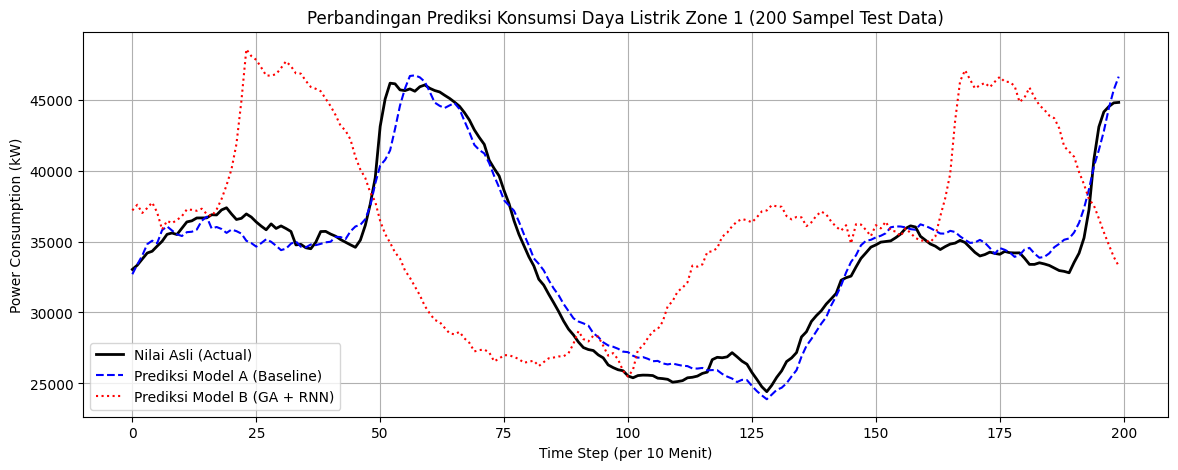

In [ ]:
import matplotlib.pyplot as plt

# 1. Ambil 200 sampel data uji pertama untuk visualisasi yang jelas
sample_len = 200

# Evaluasi Model A pada data sampel
model_A.eval()
with torch.no_grad():
    preds_A = model_A(X_test[:sample_len].to(device)).cpu().numpy()

# Evaluasi Model B pada data sampel
model_B.eval()
with torch.no_grad():
    preds_B = model_B(X_test_B[:sample_len].to(device)).cpu().numpy()

# Kembalikan skala ke satuan Watt asli (Inverse Transform)
actual_unscaled = scaler_y.inverse_transform(y_test[:sample_len].numpy())
preds_A_unscaled = scaler_y.inverse_transform(preds_A)
preds_B_unscaled = scaler_y.inverse_transform(preds_B)

# 2. Plot Grafik Perbandingan untuk Zone 1 Power Consumption
plt.figure(figsize=(14, 5))
plt.plot(actual_unscaled[:, 0], label='Nilai Asli (Actual)', color='black', linewidth=2)
plt.plot(preds_A_unscaled[:, 0], label='Prediksi Model A (Baseline)', color='blue', linestyle='--')
plt.plot(preds_B_unscaled[:, 0], label='Prediksi Model B (GA + RNN)', color='red', linestyle=':')

plt.title('Perbandingan Prediksi Konsumsi Daya Listrik Zone 1 (200 Sampel Test Data)')
plt.xlabel('Time Step (per 10 Menit)')
plt.ylabel('Power Consumption (kW)')
plt.legend()
plt.grid(True)
plt.show()